# WEEKLY AGGREGATION VERSION of NN, LSTM & GRU Forecasting — Rainfall Jakarta (2010-2026)
**Source:** NASA/POWER MERRA-2 | PRECTOTCORR (mm/day)

Notebook ini menjalankan model NN, LSTM, dan GRU untuk forecasting curah hujan.

Hasil evaluasi metrics dari notebook ini dimasukkan ke tabel perbandingan di R.


In [ ]:
# install dependencies
!pip install openpyxl -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

torch.manual_seed(42)
np.random.seed(42)

## 1. Load dan Preprocessing Data

In [ ]:
df = pd.read_excel('Dataset16Tahun.xlsx')
df["Date"] = pd.to_datetime(
    dict(
        year=df["YEAR"],
        month=df["MO"],
        day=df["DOY"]
    )
)
df = df.sort_values('Date').reset_index(drop=True)

print(df.shape)
df.head()

(5845, 5)


,YEAR,MO,DOY,PRECTOTCORR,Date
0,2010,1,1,0.82,2010-01-01
1,2010,1,2,6.52,2010-01-02
2,2010,1,3,3.46,2010-01-03
3,2010,1,4,3.20,2010-01-04
4,2010,1,5,3.82,2010-01-05


In [ ]:
# WEEKLY AGGREGATION (SAME AS R VERSION)
# 7-DAY BLOCKS, NOT ISO WEEK

import pandas as pd
import numpy as np

# make sure Date is datetime
df['Date'] = pd.to_datetime(df['Date'])

# sort by date
df = df.sort_values('Date').reset_index(drop=True)

# create rolling 7-day block ID
df['WEEK_ID'] = (
    (df['Date'] - df['Date'].min()).dt.days // 7
) + 1

# aggregate weekly rainfall
weekly = (
    df.groupby('WEEK_ID')
      .agg(
          week_start = ('Date', 'min'),
          week_end   = ('Date', 'max'),
          rain_weekly = ('PRECTOTCORR', 'sum')
      )
      .reset_index()
)

# additional variables
weekly['t'] = np.arange(1, len(weekly)+1)

weekly['rain_log'] = np.log1p(
    weekly['rain_weekly']
)

print(f"Weekly data: {len(weekly)} observations")

print(
    "Period:",
    weekly['week_start'].min(),
    "to",
    weekly['week_end'].max()
)

weekly.head()

Weekly data: 835 observations
Period: 2010-01-01 00:00:00 to 2026-01-01 00:00:00


,WEEK_ID,week_start,week_end,rain_weekly,t,rain_log
0,1,2010-01-01,2010-01-07,30.79,1,3.459152
1,2,2010-01-08,2010-01-14,97.18,2,4.586803
2,3,2010-01-15,2010-01-21,148.91,3,5.010035
3,4,2010-01-22,2010-01-28,77.58,4,4.364117
4,5,2010-01-29,2010-02-04,73.80,5,4.314818


In [ ]:
# =========================================
# TRAIN TEST SPLIT (80:20 CHRONOLOGICAL)
# FOR NN / LSTM / GRU
# =========================================

from sklearn.preprocessing import MinMaxScaler

# ONLY rainfall variable
rain = weekly['rain_weekly'].values.reshape(-1, 1)

# split size
n = len(rain)

n_train = int(n * 0.8)
n_test  = n - n_train

# chronological split
train_raw = rain[:n_train]
test_raw  = rain[n_train:]

# scaler fit ONLY on training
# to avoid data leakage
scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_raw)
test_scaled  = scaler.transform(test_raw)

# timeline info
print(f"Train: {n_train} weeks | Test: {n_test} weeks")

print(
    "Train period:",
    weekly['week_start'].iloc[0],
    "to",
    weekly['week_end'].iloc[n_train - 1]
)

print(
    "Test period :",
    weekly['week_start'].iloc[n_train],
    "to",
    weekly['week_end'].iloc[-1]
)

Train: 668 weeks | Test: 167 weeks
Train period: 2010-01-01 00:00:00 to 2022-10-20 00:00:00
Test period : 2022-10-21 00:00:00 to 2026-01-01 00:00:00


In [ ]:
def create_sequences(data_scaled, full_scaled, seq_len, start_idx, n_samples):
    """Buat sliding window. Untuk test, context diambil dari akhir training."""
    context = full_scaled[start_idx - seq_len: start_idx]
    combined = np.concatenate([context, data_scaled])
    X, y = [], []
    for i in range(n_samples):
        X.append(combined[i: i + seq_len])
        y.append(combined[i + seq_len])
    return np.array(X), np.array(y)

full_scaled = np.concatenate([train_scaled, test_scaled])

In [ ]:
def evaluate_metrics(actual_scaled, pred_scaled, scaler, name):
    actual = scaler.inverse_transform(actual_scaled.reshape(-1, 1)).flatten()
    pred   = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mae  = mean_absolute_error(actual, pred)
    mask = actual > 0
    mape  = np.mean(np.abs((actual[mask] - pred[mask]) / actual[mask])) * 100
    smape = np.mean(2 * np.abs(actual - pred) / (np.abs(actual) + np.abs(pred) + 1e-8)) * 100
    print(f'{name}: RMSE={rmse:.4f} | MAE={mae:.4f} | MAPE={mape:.2f}% | SMAPE={smape:.2f}%')
    return {'RMSE': round(rmse, 4), 'MAE': round(mae, 4),
            'MAPE': round(mape, 2), 'SMAPE': round(smape, 2),
            'actual': actual, 'pred': pred}

## 2. Neural Network (NN)

menggunakan lag bulanan sebagai input, lalu diproses lewat hidden layer non-linear.
Input lag ditentukan dari PACF yang signifikan. Dicoba berbagai kombinasi:
- Naikkan nodes dulu selama RMSE masih turun
- Tambah hidden layer kalau udah mentok


In [ ]:
SEQ_LEN_NN = 52
# alasan: dari PACF monthly, lag 1-3 umumnya signifikan
# 3 bulan = satu kuartal, secara praktis masuk akal untuk rainfall

X_train_nn, y_train_nn = create_sequences(train_scaled, full_scaled,
                                           SEQ_LEN_NN, n_train, n_train)
X_test_nn,  y_test_nn  = create_sequences(test_scaled,  full_scaled,
                                           SEQ_LEN_NN, n_train, n_test)
print(f'NN X_train: {X_train_nn.shape} | X_test: {X_test_nn.shape}')

NN X_train: (668, 52, 1) | X_test: (167, 52, 1)


In [ ]:
class NNModel(nn.Module):
    """Feedforward NN, bisa 1 atau 2 hidden layer."""
    def __init__(self, input_size, hidden_layers, dropout_rate=0.2):
        super(NNModel, self).__init__()
        layers = []
        prev = input_size
        for h in hidden_layers:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout_rate)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x.squeeze(-1))


def train_nn(model, X_tr, y_tr, epochs=300, lr=0.001, batch_size=16,
             patience=30):
    """Training dengan early stopping."""
    # validation split dari training (10% terakhir)
    val_size  = max(1, int(len(X_tr) * 0.1))
    X_val, y_val = X_tr[-val_size:], y_tr[-val_size:]
    X_tr2, y_tr2 = X_tr[:-val_size], y_tr[:-val_size]

    dataset   = TensorDataset(torch.FloatTensor(X_tr2), torch.FloatTensor(y_tr2))
    loader    = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    wait = 0
    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb).squeeze(), yb.squeeze())
            loss.backward()
            optimizer.step()
        # cek validation loss
        model.eval()
        with torch.no_grad():
            val_pred = model(torch.FloatTensor(X_val)).squeeze().numpy()
            val_loss = mean_squared_error(y_val, val_pred)
        model.train()
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break
        if (epoch + 1) % 100 == 0:
            print(f'  Epoch {epoch+1} | val_loss: {val_loss:.6f}')

In [ ]:
# kombinasi hidden layer yang dicoba
# sesuai catatan: tambah nodes dulu, baru tambah hidden layer
nn_configs = [
    {'hidden': [16],       'label': 'NN(lag3, 1HL-16)'},
    {'hidden': [32],       'label': 'NN(lag3, 1HL-32)'},
    {'hidden': [64],       'label': 'NN(lag3, 1HL-64)'},
    {'hidden': [128],      'label': 'NN(lag3, 1HL-128)'},
    {'hidden': [64, 32],   'label': 'NN(lag3, 2HL-64,32)'},
    {'hidden': [128, 64],  'label': 'NN(lag3, 2HL-128,64)'},
]

nn_results = []
for cfg in nn_configs:
    print(f"Training {cfg['label']}...")
    torch.manual_seed(42)
    model = NNModel(input_size=SEQ_LEN_NN, hidden_layers=cfg['hidden'])
    train_nn(model, X_train_nn, y_train_nn, epochs=300)
    model.eval()
    with torch.no_grad():
        pred_test = model(torch.FloatTensor(X_test_nn)).squeeze().numpy()
    res = evaluate_metrics(y_test_nn, pred_test, scaler, cfg['label'])
    nn_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

nn_df = pd.DataFrame(nn_results)
print('\n--- NN Summary ---')
print(nn_df.to_string(index=False))

Training NN(lag3, 1HL-16)...
  Early stopping at epoch 33
NN(lag3, 1HL-16): RMSE=33.7317 | MAE=23.2330 | MAPE=2188.48% | SMAPE=65.07%
Training NN(lag3, 1HL-32)...
  Early stopping at epoch 31
NN(lag3, 1HL-32): RMSE=33.1963 | MAE=22.6467 | MAPE=1614.42% | SMAPE=63.88%
Training NN(lag3, 1HL-64)...
  Early stopping at epoch 31
NN(lag3, 1HL-64): RMSE=33.6866 | MAE=22.9726 | MAPE=1929.97% | SMAPE=62.79%
Training NN(lag3, 1HL-128)...
  Early stopping at epoch 31
NN(lag3, 1HL-128): RMSE=34.1523 | MAE=23.9882 | MAPE=1544.50% | SMAPE=65.33%
Training NN(lag3, 2HL-64,32)...
  Early stopping at epoch 32
NN(lag3, 2HL-64,32): RMSE=34.9450 | MAE=24.3359 | MAPE=2258.99% | SMAPE=64.00%
Training NN(lag3, 2HL-128,64)...
  Early stopping at epoch 31
NN(lag3, 2HL-128,64): RMSE=35.3690 | MAE=24.6187 | MAPE=1614.63% | SMAPE=65.74%

--- NN Summary ---
               Model    RMSE     MAE    MAPE  SMAPE
    NN(lag3, 1HL-16) 33.7317 23.2330 2188.48  65.07
    NN(lag3, 1HL-32) 33.1963 22.6467 1614.42  63.88
    

Best NN: NN(lag3, 1HL-32)
  Early stopping at epoch 31
Best NN (test): RMSE=33.1963 | MAE=22.6467 | MAPE=1614.42% | SMAPE=63.88%


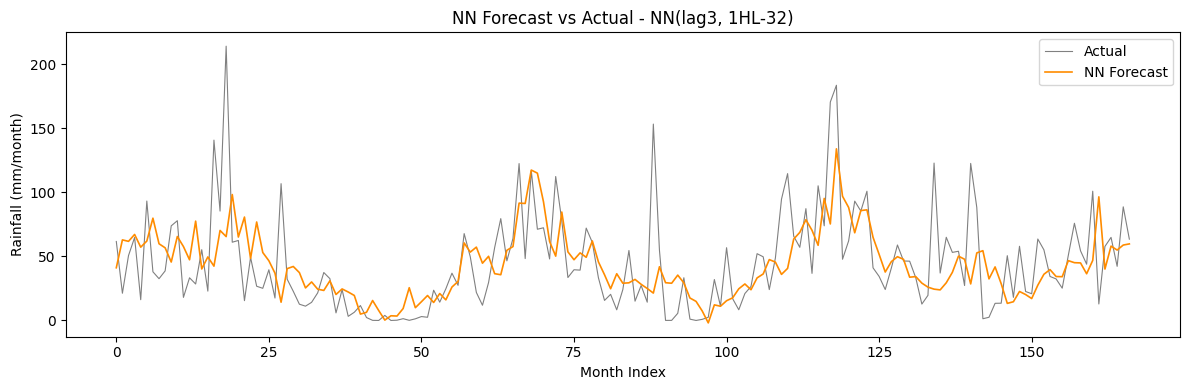

In [ ]:
# plot best NN
best_nn_idx = nn_df['RMSE'].idxmin()
best_nn_cfg = nn_configs[best_nn_idx]
print(f'Best NN: {best_nn_cfg["label"]}')

torch.manual_seed(42)
best_nn = NNModel(SEQ_LEN_NN, best_nn_cfg['hidden'])
train_nn(best_nn, X_train_nn, y_train_nn)
best_nn.eval()
with torch.no_grad():
    pred_nn = best_nn(torch.FloatTensor(X_test_nn)).squeeze().numpy()
res_nn = evaluate_metrics(y_test_nn, pred_nn, scaler, 'Best NN (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_nn['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_nn['pred'],   color='darkorange', linewidth=1.2, label='NN Forecast')
plt.title(f'NN Forecast vs Actual - {best_nn_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 4. LSTM
LSTM menggunakan sequence bulanan yang lebih panjang (6 bulan) karena LSTM
dirancang untuk menangkap long-term dependency.
Dropout diterapkan untuk mencegah overfitting pada dataset bulanan yang kecil.
Early stopping digunakan agar training berhenti saat validation loss tidak membaik.


In [ ]:
SEQ_LEN = 52  # 6 bulan = setengah tahun, cocok untuk tangkap pola seasonal

X_train_lstm, y_train_lstm = create_sequences(train_scaled, full_scaled,
                                               SEQ_LEN, n_train, n_train)
X_test_lstm,  y_test_lstm  = create_sequences(test_scaled,  full_scaled,
                                               SEQ_LEN, n_train, n_test)

X_train_t = torch.FloatTensor(X_train_lstm)
y_train_t = torch.FloatTensor(y_train_lstm)
X_test_t  = torch.FloatTensor(X_test_lstm)
y_test_t  = torch.FloatTensor(y_test_lstm)
print(f'LSTM/GRU X_train: {X_train_t.shape} | X_test: {X_test_t.shape}')

LSTM/GRU X_train: torch.Size([668, 52, 1]) | X_test: torch.Size([167, 52, 1])


In [ ]:
class RNNModel(nn.Module):
    def __init__(self, model_type, input_size, hidden_size, num_layers, dropout=0.2):
        super(RNNModel, self).__init__()
        rnn_dropout = dropout if num_layers > 1 else 0
        if model_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers,
                               batch_first=True, dropout=rnn_dropout)
        elif model_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers,
                              batch_first=True, dropout=rnn_dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.dropout(out[:, -1, :])
        return self.fc(out)


def train_rnn(model, X_tr, y_tr, epochs=200, lr=0.001, batch_size=16, patience=25):
    """Training dengan early stopping untuk RNN."""
    val_size  = max(1, int(len(X_tr) * 0.1))
    X_val, y_val = X_tr[-val_size:], y_tr[-val_size:]
    X_tr2, y_tr2 = X_tr[:-val_size], y_tr[:-val_size]

    dataset   = TensorDataset(X_tr2, y_tr2)
    loader    = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    best_val = float('inf')
    wait = 0
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()
            loss = criterion(model(xb).squeeze(), yb.squeeze())
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_pred = model(X_val).squeeze().numpy()
            val_loss = mean_squared_error(y_val.numpy(), val_pred)
        if val_loss < best_val:
            best_val = val_loss
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f'  Early stopping at epoch {epoch+1}')
                break
        if (epoch + 1) % 50 == 0:
            print(f'  Epoch {epoch+1} | val_loss: {val_loss:.6f}')

In [ ]:
# kombinasi hidden layer yang dicoba
lstm_configs = [
    {'hidden_size': 16,  'num_layers': 1, 'label': 'LSTM(16, 1L)'},
    {'hidden_size': 32,  'num_layers': 1, 'label': 'LSTM(32, 1L)'},
    {'hidden_size': 64,  'num_layers': 1, 'label': 'LSTM(64, 1L)'},
    {'hidden_size': 128, 'num_layers': 1, 'label': 'LSTM(128, 1L)'},
    {'hidden_size': 32,  'num_layers': 2, 'label': 'LSTM(32, 2L)'},
    {'hidden_size': 64,  'num_layers': 2, 'label': 'LSTM(64, 2L)'},
]

lstm_results = []
for cfg in lstm_configs:
    print(f"\nTraining {cfg['label']}...")
    torch.manual_seed(42)
    model = RNNModel('LSTM', 1, cfg['hidden_size'], cfg['num_layers'])
    train_rnn(model, X_train_t, y_train_t)
    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t).squeeze().numpy()
    res = evaluate_metrics(y_test_t.numpy(), pred_test, scaler, cfg['label'])
    lstm_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

lstm_df = pd.DataFrame(lstm_results)
print('\n--- LSTM Summary ---')
print(lstm_df.to_string(index=False))


Training LSTM(16, 1L)...
  Epoch 50 | val_loss: 0.005672
  Epoch 100 | val_loss: 0.005751
  Early stopping at epoch 106
LSTM(16, 1L): RMSE=32.5031 | MAE=23.2986 | MAPE=1915.80% | SMAPE=63.00%

Training LSTM(32, 1L)...
  Epoch 50 | val_loss: 0.005792
  Early stopping at epoch 62
LSTM(32, 1L): RMSE=32.5899 | MAE=23.3632 | MAPE=1992.03% | SMAPE=63.16%

Training LSTM(64, 1L)...
  Early stopping at epoch 49
LSTM(64, 1L): RMSE=32.4571 | MAE=23.1068 | MAPE=1803.62% | SMAPE=61.93%

Training LSTM(128, 1L)...
  Epoch 50 | val_loss: 0.005769
  Early stopping at epoch 52
LSTM(128, 1L): RMSE=32.5774 | MAE=23.4991 | MAPE=2084.05% | SMAPE=63.81%

Training LSTM(32, 2L)...
  Early stopping at epoch 45
LSTM(32, 2L): RMSE=32.5365 | MAE=23.3763 | MAPE=1862.12% | SMAPE=62.91%

Training LSTM(64, 2L)...
  Early stopping at epoch 48
LSTM(64, 2L): RMSE=32.5399 | MAE=23.4295 | MAPE=2033.44% | SMAPE=63.18%

--- LSTM Summary ---
        Model    RMSE     MAE        MAPE     SMAPE
 LSTM(16, 1L) 32.5031 23.2986 19

Best LSTM: LSTM(64, 1L)
  Early stopping at epoch 49
Best LSTM (test): RMSE=32.4571 | MAE=23.1068 | MAPE=1803.62% | SMAPE=61.93%


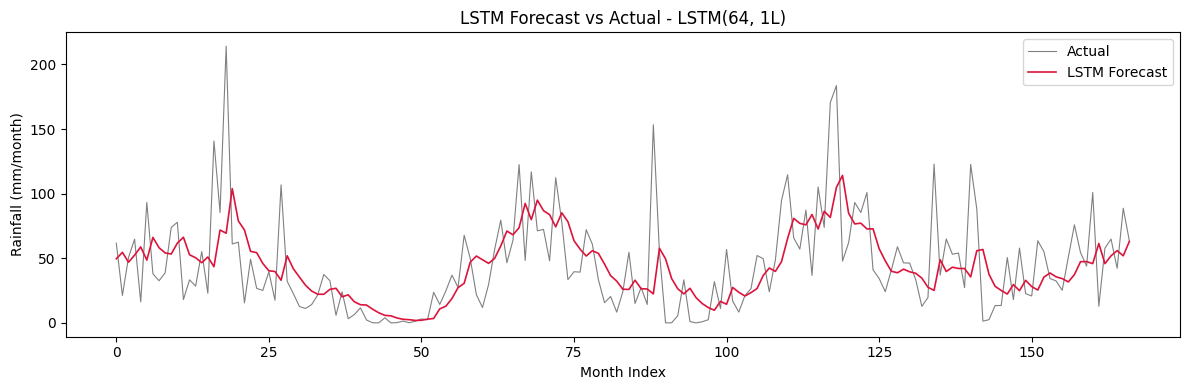

In [ ]:
# retrain best LSTM untuk plot
best_lstm_idx = lstm_df['RMSE'].idxmin()
best_lstm_cfg = lstm_configs[best_lstm_idx]
print(f'Best LSTM: {best_lstm_cfg["label"]}')

torch.manual_seed(42)
best_lstm = RNNModel('LSTM', 1, best_lstm_cfg['hidden_size'], best_lstm_cfg['num_layers'])
train_rnn(best_lstm, X_train_t, y_train_t)
best_lstm.eval()
with torch.no_grad():
    pred_lstm = best_lstm(X_test_t).squeeze().numpy()
res_lstm = evaluate_metrics(y_test_t.numpy(), pred_lstm, scaler, 'Best LSTM (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_lstm['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_lstm['pred'],   color='crimson', linewidth=1.2, label='LSTM Forecast')
plt.title(f'LSTM Forecast vs Actual - {best_lstm_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. GRU

GRU adalah versi yang lebih efisien dari LSTM.
Menggunakan sequence length yang sama (6 bulan) agar perbandingan fair.
Karena parameter lebih sedikit, GRU lebih cepat dan sering menghindari overfitting
pada dataset kecil seperti data bulanan 6 tahun ini.

In [ ]:
gru_configs = [
    {'hidden_size': 16,  'num_layers': 1, 'label': 'GRU(16, 1L)'},
    {'hidden_size': 32,  'num_layers': 1, 'label': 'GRU(32, 1L)'},
    {'hidden_size': 64,  'num_layers': 1, 'label': 'GRU(64, 1L)'},
    {'hidden_size': 128, 'num_layers': 1, 'label': 'GRU(128, 1L)'},
    {'hidden_size': 32,  'num_layers': 2, 'label': 'GRU(32, 2L)'},
    {'hidden_size': 64,  'num_layers': 2, 'label': 'GRU(64, 2L)'},
]

gru_results = []
for cfg in gru_configs:
    print(f"\nTraining {cfg['label']}...")
    torch.manual_seed(42)
    model = RNNModel('GRU', 1, cfg['hidden_size'], cfg['num_layers'])
    train_rnn(model, X_train_t, y_train_t)
    model.eval()
    with torch.no_grad():
        pred_test = model(X_test_t).squeeze().numpy()
    res = evaluate_metrics(y_test_t.numpy(), pred_test, scaler, cfg['label'])
    gru_results.append({'Model': cfg['label'], **{k: res[k] for k in ['RMSE','MAE','MAPE','SMAPE']}})

gru_df = pd.DataFrame(gru_results)
print('\n--- GRU Summary ---')
print(gru_df.to_string(index=False))


Training GRU(16, 1L)...
  Early stopping at epoch 40
GRU(16, 1L): RMSE=33.6744 | MAE=23.9373 | MAPE=2386.06% | SMAPE=64.92%

Training GRU(32, 1L)...
  Epoch 50 | val_loss: 0.005549
  Early stopping at epoch 100
GRU(32, 1L): RMSE=33.5050 | MAE=23.6583 | MAPE=1761.05% | SMAPE=63.71%

Training GRU(64, 1L)...
  Epoch 50 | val_loss: 0.005751
  Early stopping at epoch 66
GRU(64, 1L): RMSE=33.6784 | MAE=23.5038 | MAPE=1358.21% | SMAPE=61.69%

Training GRU(128, 1L)...
  Epoch 50 | val_loss: 0.005749
  Early stopping at epoch 60
GRU(128, 1L): RMSE=33.6350 | MAE=23.5872 | MAPE=1540.52% | SMAPE=63.07%

Training GRU(32, 2L)...
  Epoch 50 | val_loss: 0.005608
  Early stopping at epoch 96
GRU(32, 2L): RMSE=33.4780 | MAE=23.4008 | MAPE=1450.35% | SMAPE=62.50%

Training GRU(64, 2L)...
  Epoch 50 | val_loss: 0.005806
  Early stopping at epoch 64
GRU(64, 2L): RMSE=33.7509 | MAE=23.6682 | MAPE=1570.88% | SMAPE=62.67%

--- GRU Summary ---
       Model    RMSE     MAE        MAPE     SMAPE
 GRU(16, 1L) 33

Best GRU: GRU(32, 2L)
  Epoch 50 | val_loss: 0.005608
  Early stopping at epoch 96
Best GRU (test): RMSE=33.4780 | MAE=23.4008 | MAPE=1450.35% | SMAPE=62.50%


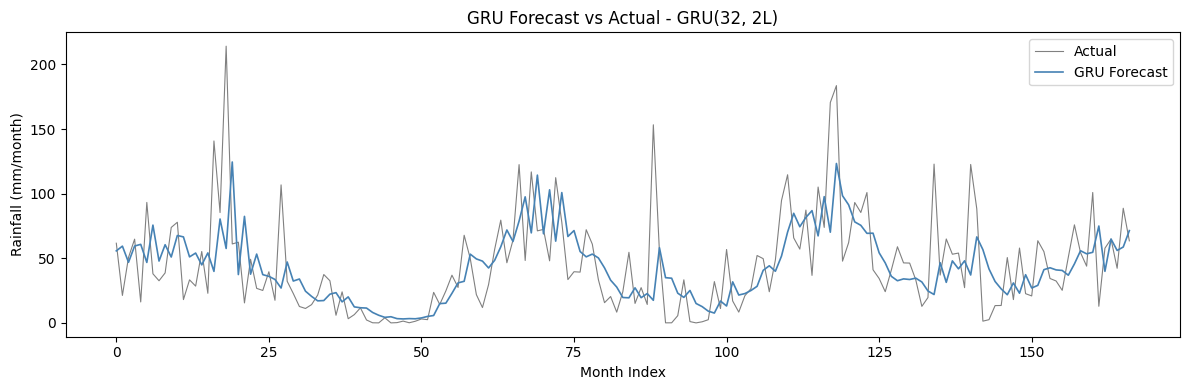

In [ ]:
best_gru_idx = gru_df['RMSE'].idxmin()
best_gru_cfg = gru_configs[best_gru_idx]
print(f'Best GRU: {best_gru_cfg["label"]}')

torch.manual_seed(42)
best_gru = RNNModel('GRU', 1, best_gru_cfg['hidden_size'], best_gru_cfg['num_layers'])
train_rnn(best_gru, X_train_t, y_train_t)
best_gru.eval()
with torch.no_grad():
    pred_gru = best_gru(X_test_t).squeeze().numpy()
res_gru = evaluate_metrics(y_test_t.numpy(), pred_gru, scaler, 'Best GRU (test)')

plt.figure(figsize=(12, 4))
plt.plot(res_gru['actual'], color='grey', linewidth=0.8, label='Actual')
plt.plot(res_gru['pred'],   color='steelblue', linewidth=1.2, label='GRU Forecast')
plt.title(f'GRU Forecast vs Actual - {best_gru_cfg["label"]}')
plt.xlabel('Month Index'); plt.ylabel('Rainfall (mm/month)')
plt.legend(); plt.tight_layout(); plt.show()

## 5. Summary — Nilai untuk dimasukkan ke R Markdown

In [ ]:
def eval_train(model, X_train, y_train, scaler, name):
    model.eval()
    with torch.no_grad():
        pred_train = model(torch.FloatTensor(X_train)).squeeze().numpy()
    return evaluate_metrics(y_train, pred_train, scaler, f'{name} (train)')

res_nn_train   = eval_train(best_nn,   X_train_nn,   y_train_nn,   scaler, 'NN')
res_lstm_train = eval_train(best_lstm, X_train_t.numpy(), y_train_t.numpy(), scaler, 'LSTM')
res_gru_train  = eval_train(best_gru,  X_train_t.numpy(), y_train_t.numpy(), scaler, 'GRU')

NN (train): RMSE=28.0248 | MAE=18.2106 | MAPE=414.25% | SMAPE=53.46%
LSTM (train): RMSE=32.6972 | MAE=21.1265 | MAPE=388.89% | SMAPE=60.01%
GRU (train): RMSE=31.5784 | MAE=20.5691 | MAPE=303.12% | SMAPE=59.59%


In [ ]:
print(f'rmse_nn_test   <- {res_nn["RMSE"]}')
print(f'mae_nn_test    <- {res_nn["MAE"]}')
print(f'mape_nn_test   <- {res_nn["MAPE"]}')
print(f'rmse_lstm_test <- {res_lstm["RMSE"]}')
print(f'mae_lstm_test  <- {res_lstm["MAE"]}')
print(f'mape_lstm_test <- {res_lstm["MAPE"]}')
print(f'rmse_gru_test  <- {res_gru["RMSE"]}')
print(f'mae_gru_test   <- {res_gru["MAE"]}')
print(f'mape_gru_test  <- {res_gru["MAPE"]}')
print()
print('Detail NN:') ; print(nn_df.to_string(index=False))
print('\nDetail LSTM:') ; print(lstm_df.to_string(index=False))
print('\nDetail GRU:')  ; print(gru_df.to_string(index=False))

rmse_nn_test   <- 33.1963
mae_nn_test    <- 22.6467
mape_nn_test   <- 1614.42
rmse_lstm_test <- 32.4571
mae_lstm_test  <- 23.1068
mape_lstm_test <- 1803.6199951171875
rmse_gru_test  <- 33.478
mae_gru_test   <- 23.4008
mape_gru_test  <- 1450.3499755859375

Detail NN:
               Model    RMSE     MAE    MAPE  SMAPE
    NN(lag3, 1HL-16) 33.7317 23.2330 2188.48  65.07
    NN(lag3, 1HL-32) 33.1963 22.6467 1614.42  63.88
    NN(lag3, 1HL-64) 33.6866 22.9726 1929.97  62.79
   NN(lag3, 1HL-128) 34.1523 23.9882 1544.50  65.33
 NN(lag3, 2HL-64,32) 34.9450 24.3359 2258.99  64.00
NN(lag3, 2HL-128,64) 35.3690 24.6187 1614.63  65.74

Detail LSTM:
        Model    RMSE     MAE        MAPE     SMAPE
 LSTM(16, 1L) 32.5031 23.2986 1915.800049 63.000000
 LSTM(32, 1L) 32.5899 23.3632 1992.030029 63.160000
 LSTM(64, 1L) 32.4571 23.1068 1803.619995 61.930000
LSTM(128, 1L) 32.5774 23.4991 2084.050049 63.810001
 LSTM(32, 2L) 32.5365 23.3763 1862.119995 62.910000
 LSTM(64, 2L) 32.5399 23.4295 2033.439941 6